# MOMENT SageMaker Model

## 1. Set up the environment

Install the dependencies.

In [1]:
%pip install --quiet "sagemaker==3.30.0" plotly nbformat


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import io
import json
import datetime
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sagemaker.core.helper.session_helper import Session, get_execution_role
from sagemaker.core.resources import Model, TransformJob, EndpointConfig, Endpoint
from sagemaker.core.shapes import (
    ContainerDefinition,
    TransformInput,
    TransformDataSource,
    TransformS3DataSource,
    TransformOutput,
    TransformResources,
    ProductionVariant,
)

# SageMaker session
session = Session()

# SageMaker role
role = get_execution_role()

# S3 bucket
bucket = "sagemaker-moment-anomaly-detection"

# EC2 instance
instance_type = "ml.g4dn.xlarge"

# AWS account ID
account = session.account_id()

# AWS region
region = session.boto_region_name

# Model ECR image
ecr_uri = f"{account}.dkr.ecr.{region}.amazonaws.com/sagemaker-moment-anomaly-detection:latest"

# Model S3 URI
s3_uri = f"s3://{bucket}/moment-1-large/model.tar.gz"

# Suffix for the names of the model, the batch transform job and the endpoint
suffix = datetime.datetime.now().strftime("%Y-%m-%d-%H-%M-%S")

Define a function for plotting the time series. 

In [3]:
def plot(
        df: pd.DataFrame,
        highlight_steps: int = 48,
        plot_width: int = 800,
        subplot_height: int = 240,
) -> go.Figure:
    """
    Input:
        df              : long-format data frame with id, timestamp, value, and optionally reconstruction and error
        highlight_steps : width of the band centred on each time series' largest reconstruction error, in time steps
                          (0 for no band)
    Output:
        plotly Figure, one subplot per time series
    """
    # Color scheme
    TEXT = "#24292f"  # text
    LINE = "#cecece"  # gray-7: axis lines
    GRID = "#e8e8e8"  # gray-4: grid lines
    OBSERVED = "#8d8d8d"  # gray-9: observed values
    RECONSTRUCTED = "#0d74ce"  # blue-11: reconstruction
    HIGHLIGHT = "#fff7c2"  # amber-3: band around the largest reconstruction error

    # One group per time series, sorted by id, with its rows in time order
    groups = df.sort_values("timestamp").groupby("id")

    fig = make_subplots(rows=groups.ngroups, cols=1, shared_xaxes=True, vertical_spacing=0.04)

    for row, (id, g) in enumerate(groups, start=1):
        first = row == 1  # show each legend entry once

        # Observed values, and the reconstruction if there is one
        for column, name, color, width in [
            ("value", "Observed", OBSERVED, 1),
            ("reconstruction", "Reconstruction", RECONSTRUCTED, 1.5),
        ]:
            if column not in g:
                continue
            fig.add_scatter(
                x=g["timestamp"],
                y=g[column],
                mode="lines",
                name=name,
                legendgroup=name,
                showlegend=first,
                line=dict(color=color, width=width),
                row=row,
                col=1,
            )

        # Band of `highlight_steps` time steps centred on the largest absolute
        # reconstruction error, cut at the ends of the series, if there is an error
        if "error" in g and highlight_steps > 0:
            peak = g["error"].abs().to_numpy().argmax()  # position in the sorted series
            start = max(peak - highlight_steps // 2, 0)
            end = min(peak + highlight_steps // 2, len(g) - 1)
            fig.add_vrect(
                x0=str(g["timestamp"].iloc[start]),
                x1=str(g["timestamp"].iloc[end]),
                fillcolor=HIGHLIGHT,
                line_width=0,
                layer="below",
                name="Largest reconstruction error",
                legendgroup="Largest reconstruction error",
                showlegend=first,
                row=row,
                col=1,
            )

    # Same style for all axes
    axes = dict(mirror=True, linecolor=LINE, gridcolor=GRID, gridwidth=0.5, tickfont=dict(color=TEXT))
    fig.update_xaxes(type="date", tickformat="%b %d<br>(%a) %Y", tickangle=0, **axes)
    fig.update_yaxes(tickformat=",.0f", zeroline=False, **axes)

    fig.update_layout(
        width=plot_width,
        height=subplot_height * groups.ngroups + 100,
        paper_bgcolor="white",
        plot_bgcolor="white",
        margin=dict(t=50, b=50, l=50, r=50),
        legend=dict(
            x=0,
            y=1.0,
            yanchor="bottom",
            orientation="h",
            bgcolor="rgba(0,0,0,0)",
            font=dict(color=TEXT, size=14),
        ),
    )
    return fig


## 2. Upload the data to S3

In [4]:
dataset = pd.read_csv("sample_data/data.csv", parse_dates=["timestamp"])

In [5]:
dataset.shape

(3000, 3)

In [6]:
dataset.head()

,id,timestamp,value
0,1,2026-01-01 00:00:00,26
1,1,2026-01-01 00:30:00,28
2,1,2026-01-01 01:00:00,28
3,1,2026-01-01 01:30:00,26
4,1,2026-01-01 02:00:00,32


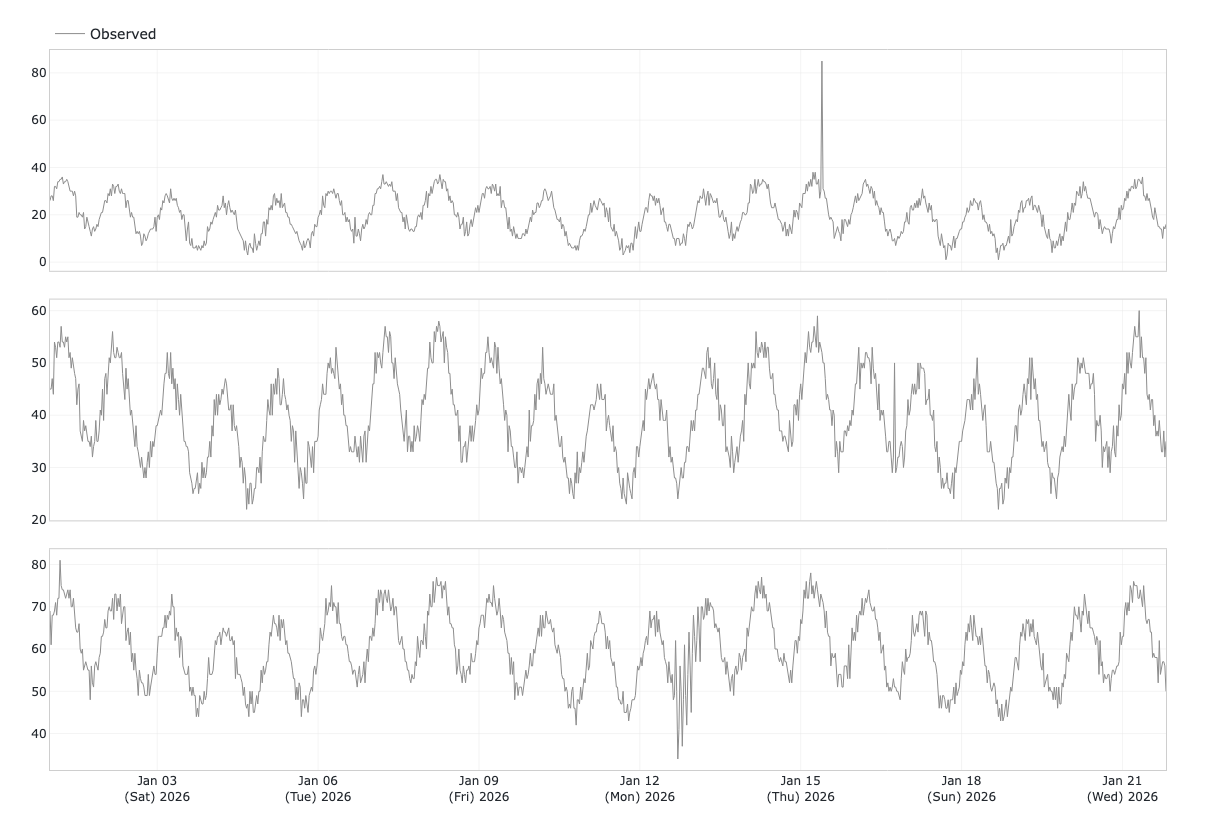

In [7]:
plot(dataset).show()

The request is a JSON object with the CSV data and the stride (optional).

In [8]:
request = {"csv": dataset.to_csv(index=False), "stride": 128}

In [9]:
data = session.upload_string_as_file_body(
    body=json.dumps(request),
    bucket=bucket,
    key="sample_data/data.json"
)

In [10]:
data

's3://sagemaker-moment-anomaly-detection/sample_data/data.json'

## 3. Create the model

In [11]:
model = Model.create(
    model_name=f"moment-model-{suffix}",
    primary_container=ContainerDefinition(
        image=ecr_uri,
        model_data_url=s3_uri,
        environment={"SAGEMAKER_MODEL_SERVER_WORKERS": "1"},
    ),
    execution_role_arn=role,
)

## 4. Run a batch transform job

Run the batch transform job.

In [12]:
transform_job = TransformJob.create(
    transform_job_name=f"moment-transform-{suffix}",
    model_name=model.model_name,
    transform_input=TransformInput(
        data_source=TransformDataSource(
            s3_data_source=TransformS3DataSource(s3_data_type="S3Prefix", s3_uri=data)
        ),
        content_type="application/json",
    ),
    transform_output=TransformOutput(
        s3_output_path=f"s3://{bucket}/batch_predictions",
        accept="text/csv",
    ),
    transform_resources=TransformResources(
        instance_type=instance_type,
        instance_count=1,
    ),
)

Wait for the batch transform job to complete.

In [13]:
session.sagemaker_client.get_waiter("transform_job_completed_or_stopped").wait(TransformJobName=transform_job.transform_job_name)

Load the predictions from S3.

In [14]:
batch_predictions = session.read_s3_file(
    bucket=bucket,
    key_prefix="batch_predictions/data.json.out"
)

batch_predictions = pd.read_csv(io.StringIO(batch_predictions), parse_dates=["timestamp"])

In [15]:
batch_predictions.shape

(3000, 5)

In [16]:
batch_predictions.head()

,id,timestamp,value,reconstruction,error
0,1,2026-01-01 00:00:00,26,21.563076,4.436924
1,1,2026-01-01 00:30:00,28,22.405012,5.594988
2,1,2026-01-01 01:00:00,28,24.021658,3.978342
3,1,2026-01-01 01:30:00,26,25.359512,0.640488
4,1,2026-01-01 02:00:00,32,26.599535,5.400465


In [17]:
batch_predictions.tail()

,id,timestamp,value,reconstruction,error
2995,3,2026-01-21 17:30:00,56,55.289030,0.710972
2996,3,2026-01-21 18:00:00,57,55.268290,1.731709
2997,3,2026-01-21 18:30:00,57,55.709152,1.290848
2998,3,2026-01-21 19:00:00,56,56.406223,0.406223
2999,3,2026-01-21 19:30:00,50,56.923347,6.923347


In [18]:
batch_predictions.isna().sum(axis=0)

id                0
timestamp         0
value             0
reconstruction    0
error             0
dtype: int64

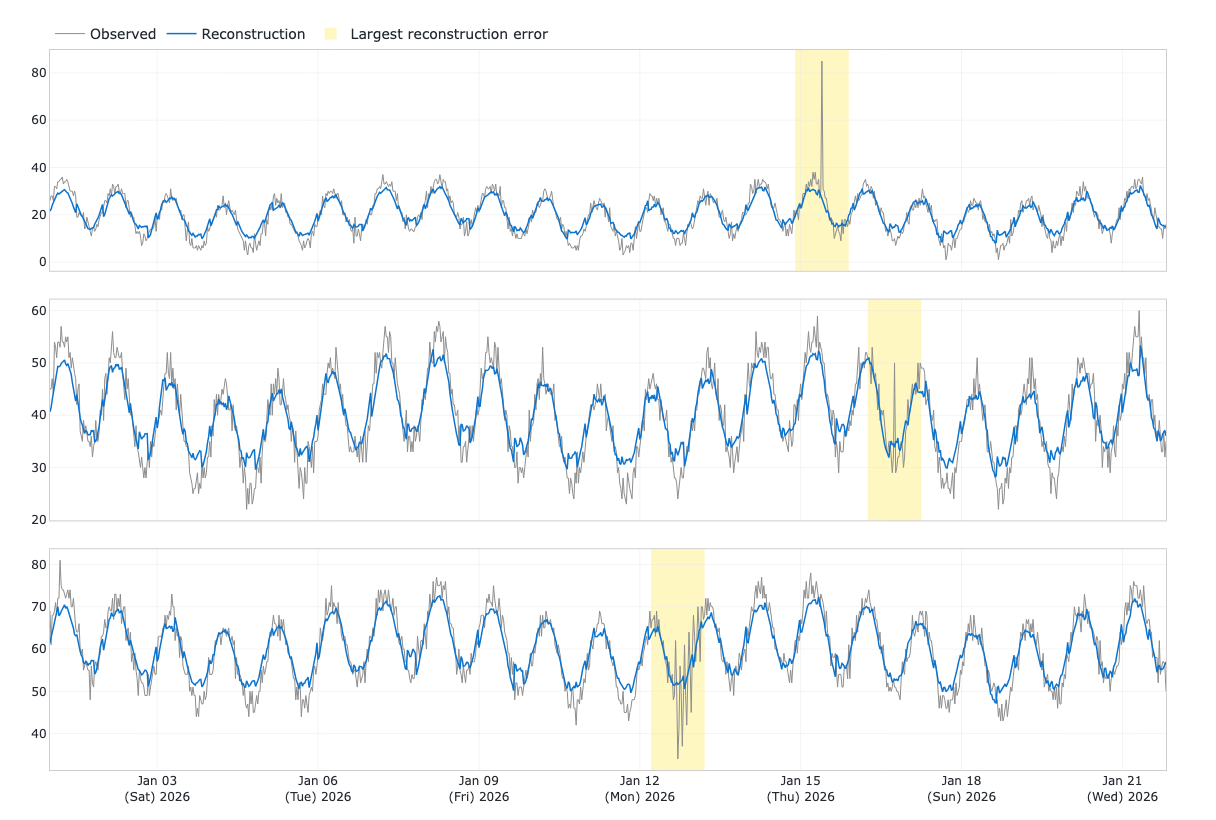

In [19]:
plot(batch_predictions).show()

## 5. Perform real-time inference

Create the endpoint configuration.

In [20]:
endpoint_config = EndpointConfig.create(
    endpoint_config_name=f"moment-endpoint-config-{suffix}",
    production_variants=[
        ProductionVariant(
            variant_name="AllTraffic",
            model_name=model.model_name,
            instance_type=instance_type,
            initial_instance_count=1,
        )
    ],
)

Create the endpoint.

In [21]:
endpoint = Endpoint.create(
    endpoint_name=f"moment-endpoint-{suffix}",
    endpoint_config_name=endpoint_config.endpoint_config_name,
)

Wait for the endpoint to be in service.

In [22]:
session.sagemaker_client.get_waiter("endpoint_in_service").wait(EndpointName=endpoint.endpoint_name)

Invoke the endpoint.

In [23]:
response = endpoint.invoke(
    body=json.dumps(request),
    content_type="application/json",
    accept="text/csv",
)

Extract the predictions from the response.

In [24]:
real_time_predictions = response.body.read().decode()

real_time_predictions = pd.read_csv(io.StringIO(real_time_predictions), parse_dates=["timestamp"])

In [25]:
real_time_predictions.shape

(3000, 5)

In [26]:
real_time_predictions.head()

,id,timestamp,value,reconstruction,error
0,1,2026-01-01 00:00:00,26,21.563078,4.436922
1,1,2026-01-01 00:30:00,28,22.405014,5.594986
2,1,2026-01-01 01:00:00,28,24.021660,3.978340
3,1,2026-01-01 01:30:00,26,25.359512,0.640488
4,1,2026-01-01 02:00:00,32,26.599535,5.400465


In [27]:
real_time_predictions.tail()

,id,timestamp,value,reconstruction,error
2995,3,2026-01-21 17:30:00,56,55.289032,0.710968
2996,3,2026-01-21 18:00:00,57,55.268295,1.731705
2997,3,2026-01-21 18:30:00,57,55.709152,1.290848
2998,3,2026-01-21 19:00:00,56,56.406227,0.406227
2999,3,2026-01-21 19:30:00,50,56.923350,6.923351


In [28]:
real_time_predictions.isna().sum(axis=0)

id                0
timestamp         0
value             0
reconstruction    0
error             0
dtype: int64

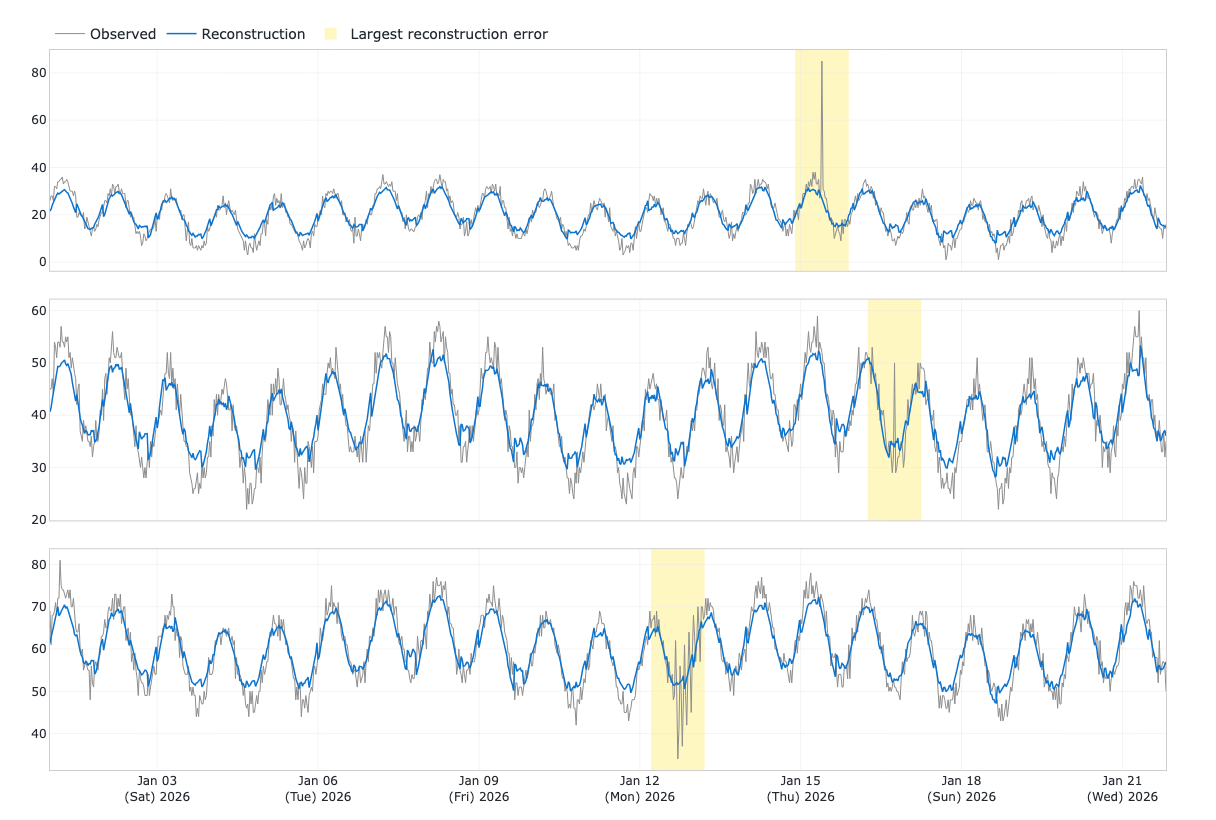

In [29]:
plot(real_time_predictions).show()

Check that the batch and real-time predictions match.

In [30]:
(batch_predictions["reconstruction"] - real_time_predictions["reconstruction"]).abs().max()

np.float64(1.3999999993075107e-05)

Delete the endpoint.

In [31]:
endpoint.delete()

Delete the endpoint configuration.

In [32]:
endpoint_config.delete()

Delete the model.

In [33]:
model.delete()